<a href="https://colab.research.google.com/github/SeungGyo-Jung/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_4%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# 오픈소스 기반 데이터 분석 4강 - 데이터 수집


## 4-1 CSV 파일 읽기

In [ ]:
import pandas as pd

## data.csv 파일 읽기

print(df)

## 4-2 JSON 파일 읽기



In [ ]:
import json
import pandas as pd

## data.json 파일 출력

## data.json 파일 DataFrame 읽기

print(df)

## 4-3 텍스트 파일 읽기 및 데이터 추출

In [ ]:
import re

## 파일(callcenter20250301.log) 오픈 및 읽기
with open('callcenter20250301.log', 'r', encoding='utf-8') as f:
    content = f.read()
## 주민등록번호 패턴 생성

## 주민등록번호 마스킹


## 마스킹된 파일(callcenter20250301_masked.log) 오픈 및 쓰기


print("주민등록번호 마스킹 완료. 'callcenter20250301_masked.log.txt' 파일로 저장되었습니다.")

## 4-4 Open-Meteo의 무료 날씨 API를 통한 특정 지역 온도 조회

In [ ]:
import requests
import json

url = "https://api.open-meteo.com/v1/forecast?=&=&current=temperature_2m"
params = {
    "latitude": "37.58638333",
    "longitude": "127.0203333",
    "current": "temperature_2m"
}

try:
    ## URL 및 파라미터 전송

    ## JSON 데이터 읽기

    print("API 응답:", data)
    print("서울시 종로구의 현재 온도는 : {0}{1} 입니다.".format(data['current']['temperature_2m'], data['current_units']['temperature_2m']))

except requests.exceptions.RequestException as e:
    print(f"API 호출 실패: {e}")
except json.JSONDecodeError as e:
    print(f"JSON 파싱 실패: {e}")

## 4-5 Selenium과 lxml을 이용한 웹 스크래핑

In [ ]:
!curl -o google-chrome-stable_current_amd64.deb https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb
!apt install ./google-chrome-stable_current_amd64.deb -y
!pip install selenium webdriver_manager

*****데이터 수집 및 작업 실행*****
2015년 / 품종(06) 수집 완료 - 97건
2016년 / 품종(06) 수집 완료 - 87건
2017년 / 품종(06) 수집 완료 - 86건
2018년 / 품종(06) 수집 완료 - 94건
2019년 / 품종(06) 수집 완료 - 97건
2020년 / 품종(06) 수집 완료 - 101건
2021년 / 품종(06) 수집 완료 - 105건
2022년 / 품종(06) 수집 완료 - 91건
2023년 / 품종(06) 수집 완료 - 105건
2024년 / 품종(06) 수집 완료 - 102건

최종 수집된 전체 데이터 개수: 965건


,ctgry_cd,ctgry_nm,exmn_dd_cnvs_prc,exmn_dd_prc,exmn_ymd,grd_cd,grd_nm,item_cd,item_nm,mrkt_cd,mrkt_nm,orgnl_reg_dt,se_cd,se_nm,sgg_cd,sgg_nm,unit,unit_sz,vrty_cd,vrty_nm
0,200,채소류,4000,4000,20150107,04,상품,211,배추,0110211,가락도매,2015-01-07T13:49:11Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
1,200,채소류,4000,4000,20150108,04,상품,211,배추,0110211,가락도매,2015-01-08T13:50:57Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
2,200,채소류,4000,4000,20150109,04,상품,211,배추,0110211,가락도매,2015-01-09T14:00:03Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
3,200,채소류,4000,4000,20150112,04,상품,211,배추,0110211,가락도매,2015-01-12T13:46:35Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
4,200,채소류,4000,4000,20150113,04,상품,211,배추,0110211,가락도매,2015-01-13T13:50:54Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동


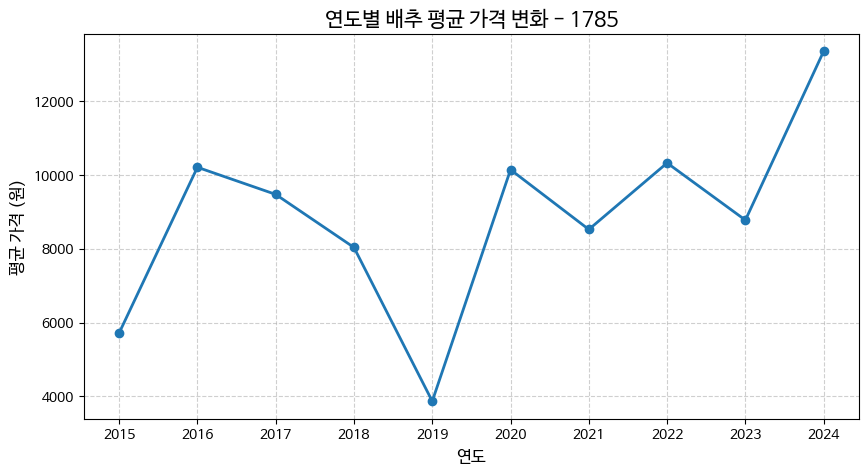

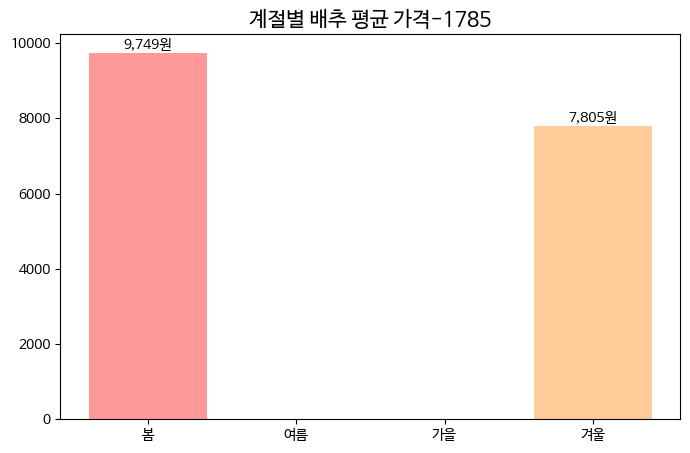

In [36]:
import requests
import pandas as pd
import time
import matplotlib.pyplot as plt

## 데이터 수집 url 및 api key 설정
url = "https://apis.data.go.kr/B552845/perDay/price"
SERVICE_KEY = "7e6f17c42495a151258f4e61b79d433bee8c4f6f1a6368a0a623377e501cf16a"

## 수집할 연도(2015년~2024년)
years = range(2015, 2025)

##품종 코드(01: 봄, 02: 여름(고랭지), 03: 가을, 06:월동)
vrty_codes = ['01', '02', '03', '06']

## 전체 데이터를 담을 리스트
all_data = []

print("*****데이터 수집 및 작업 실행*****")

for year in years:
    for vrty in vrty_codes:
        # 연도별 시작일, 종료일 설정
        start_date = f"{year}0101"
        end_date = f"{year}1231"

        ## 필수코드 값
        params = {
            "serviceKey": SERVICE_KEY,
            "pageNo": "1",
            "numOfRows": "200",
            "returnType": "JSON",
            "cond[exmn_ymd::GTE]": start_date,  # 시작일
            "cond[exmn_ymd::LTE]": end_date,    # 종료일
            "cond[se_cd::EQ]": "02",            # 중도매
            "cond[ctgry_cd::EQ]": "200",        # 채소류
            "cond[item_cd::EQ]": "211",         # 배추
            "cond[grd_cd::EQ]": "04",           # 상품
            "cond[sgg_cd::EQ]": "1101",         # 서울
            "cond[mrkt_cd::EQ]": "0110211",     # 가락도매
            "cond[vrty_cd::EQ]": vrty           # 품종코드
        }

    try:
            # API 호출
            response = requests.get(url, params=params)

            # 응답 성공 시
            if response.status_code == 200:
                data = response.json()

                # 응답 데이터에서 총 건수와 아이템 리스트 추출
                body = data.get('response', {}).get('body', {})
                total_count = body.get('totalCount', 0)
                items = body.get('items', {}).get('item', [])

                if total_count > 0:
                    # 데이터가 1건일 경우 dict 형태로 올 수 있으므로 list로 변환 처리
                    if isinstance(items, dict):
                        all_data.append(items)
                    elif isinstance(items, list):
                        all_data.extend(items)

                    print(f"{year}년 / 품종({vrty}) 수집 완료 - {total_count}건")
                else:
                    print(f"{year}년 / 품종({vrty}) 데이터 없음 (0건)")

            else:
                print(f"API 호출 에러: {response.status_code}")

    except Exception as e:
            print(f"요청 중 에러 발생 ({year}년, 품종 {vrty}): {e}")

        # 안정적인 작동을 위해 2초씩 대기
time.sleep(2.0)

## 호출 성공/실패 출력
if all_data:
        df = pd.DataFrame(all_data)
        print(f"\n최종 수집된 전체 데이터 개수: {len(df)}건")

# 수집된 데이터를 첫 5행 출력
        display(df.head())
else:
        print("오류발생. 인증키 또는 URL확인이 필요합니다.")


    #문제 3-1
if 'df' in locals(): # df가 정상적으로 생성되었는지 확인
    # 조사일자(exmn_ymd)에서 연도 추출
    df['year'] = df['exmn_ymd'].str[:4]

    # 가격 데이터의 쉼표 제거 및 foat으로 변환
    df['exmn_dd_prc'] = pd.to_numeric(df['exmn_dd_prc'].astype(str).str.replace(',', ''), errors='coerce')

    # 연도별 평균 가격
    yearly_mean = df.groupby('year')['exmn_dd_prc'].mean()

    # 한글 폰트 적용
    plt.rc('font', family='NanumBarunGothic')
    plt.rcParams['axes.unicode_minus'] = False

    # 그래프 그리기
    plt.figure(figsize=(10, 5))
    plt.plot(yearly_mean.index, yearly_mean.values, marker='o', linewidth=2, color='tab:blue')

    # 그래프 제목에 학번 표기(학번 1785)
    plt.title('연도별 배추 평균 가격 변화 - 1785', fontsize=15)
    plt.xlabel('연도', fontsize=12)
    plt.ylabel('평균 가격 (원)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)

    # 그래프 출력
    plt.show()


    #문제 3-2
    # 월(month) 추출 및 계절(season) 컬럼 추가
    month = df['exmn_ymd'].str[4:6].astype(int)
    season_map = {12:'겨울', 1:'겨울', 2:'겨울', 3:'봄', 4:'봄', 5:'봄', 6:'여름', 7:'여름', 8:'여름', 9:'가을', 10:'가을', 11:'가을'}
    df['season'] = month.map(season_map)

    #계절별 평균 가격 (데이터가 없는 계절은 0으로 표기되도록 정렬)
    seasonal_mean = df.groupby('season')['exmn_dd_prc'].mean().reindex(['봄', '여름', '가을', '겨울'], fill_value=0)

    #막대그래프 시각화
    plt.figure(figsize=(8, 5))
    bars = plt.bar(seasonal_mean.index, seasonal_mean.values, color=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99'])

    #각 막대 상단에 구체적인 수치 표시 (0원인 경우는 표시 생략)
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height):,}원', ha='center', va='bottom')

    plt.title('계절별 배추 평균 가격-1785', fontsize=15)
    plt.show()


# 실습 시나리오

## 공공데이터 포털 가입 및 데이터 신청

- [https://www.data.go.kr](https://www.data.go.kr)
- 한국환경공단 에어코리아 대기오염정보 데이터 신청

*****데이터 수집 및 작업 실행*****
2024년 / 품종(06) 수집 완료 - 102건

최종 수집된 전체 데이터 개수: 102건


,ctgry_cd,ctgry_nm,exmn_dd_cnvs_prc,exmn_dd_prc,exmn_ymd,grd_cd,grd_nm,item_cd,item_nm,mrkt_cd,mrkt_nm,orgnl_reg_dt,se_cd,se_nm,sgg_cd,sgg_nm,unit,unit_sz,vrty_cd,vrty_nm
0,200,채소류,8400,8400,20240102,04,상품,211,배추,0110211,가락도매,2024-01-02T15:35:35Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
1,200,채소류,8600,8600,20240103,04,상품,211,배추,0110211,가락도매,2024-01-03T15:44:53Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
2,200,채소류,8400,8400,20240104,04,상품,211,배추,0110211,가락도매,2024-01-04T16:10:23Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
3,200,채소류,7000,7000,20240105,04,상품,211,배추,0110211,가락도매,2024-01-08T10:23:27Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동
4,200,채소류,7600,7600,20240108,04,상품,211,배추,0110211,가락도매,2024-01-08T15:38:11Z,02,중도매,1101,서울,kg(그물망 3포기),10,06,월동


*****데이터 프레임*****
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ctgry_cd          102 non-null    object
 1   ctgry_nm          102 non-null    object
 2   exmn_dd_cnvs_prc  102 non-null    object
 3   exmn_dd_prc       102 non-null    object
 4   exmn_ymd          102 non-null    object
 5   grd_cd            102 non-null    object
 6   grd_nm            102 non-null    object
 7   item_cd           102 non-null    object
 8   item_nm           102 non-null    object
 9   mrkt_cd           102 non-null    object
 10  mrkt_nm           102 non-null    object
 11  orgnl_reg_dt      102 non-null    object
 12  se_cd             102 non-null    object
 13  se_nm             102 non-null    object
 14  sgg_cd            102 non-null    object
 15  sgg_nm            102 non-null    object
 16  unit              102 non-null    object
 17

,exmn_ymd,year,season
0,20240102,2024,겨울
1,20240103,2024,겨울
2,20240104,2024,겨울
3,20240105,2024,겨울
4,20240108,2024,겨울


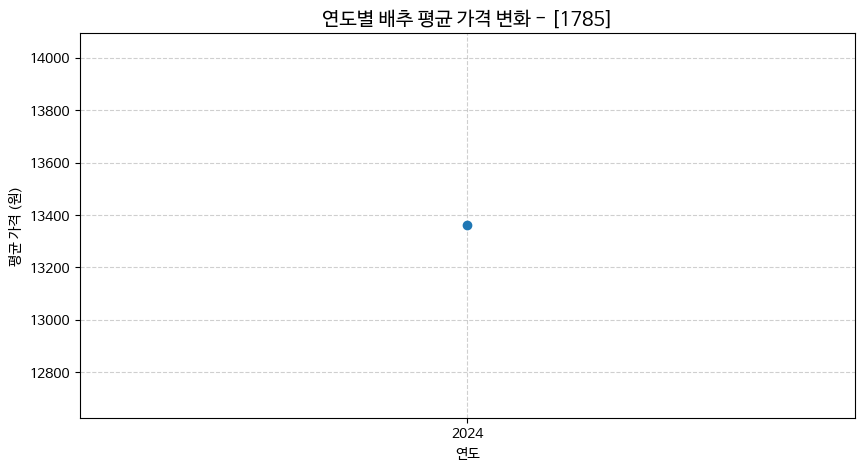

In [9]:

import requests
import pandas as pd
import time
import matplotlib.pyplot as plt


## 데이터 수집 url 및 api key 설정
url = "https://apis.data.go.kr/B552845/perDay/price"
SERVICE_KEY = "7e6f17c42495a151258f4e61b79d433bee8c4f6f1a6368a0a623377e501cf16a"

## 수집할 연도(2015년~2024년)
years = range(2015, 2025)

##품종 코드(01: 봄, 02: 여름(고랭지), 03: 가을, 06:월동)
vrty_codes = ['01', '02', '03', '06']

## 전체 데이터를 담을 리스트
all_data = []

print("*****데이터 수집 및 작업 실행*****")


for year in years:
    for vrty in vrty_codes:
        # 연도별 시작일, 종료일 설정
        start_date = f"{year}0101"
        end_date = f"{year}1231"

        ## 필수코드 값
        params = {
            "serviceKey": SERVICE_KEY,
            "pageNo": "1",
            "numOfRows": "200",
            "returnType": "JSON",
            "cond[exmn_ymd::GTE]": start_date,  # 시작일
            "cond[exmn_ymd::LTE]": end_date,    # 종료일
            "cond[se_cd::EQ]": "02",            # 중도매
            "cond[ctgry_cd::EQ]": "200",        # 채소류
            "cond[item_cd::EQ]": "211",         # 배추
            "cond[grd_cd::EQ]": "04",           # 상품
            "cond[sgg_cd::EQ]": "1101",         # 서울
            "cond[mrkt_cd::EQ]": "0110211",     # 가락도매
            "cond[vrty_cd::EQ]": vrty           # 품종코드
        }

try:
            # API 호출
            response = requests.get(url, params=params)

            # 응답 성공 시
            if response.status_code == 200:
                data = response.json()

                # 응답 데이터에서 총 건수와 아이템 리스트 추출
                body = data.get('response', {}).get('body', {})
                total_count = body.get('totalCount', 0)
                items = body.get('items', {}).get('item', [])

                if total_count > 0:
                    # 데이터가 1건일 경우 dict 형태로 올 수 있으므로 list로 변환 처리
                    if isinstance(items, dict):
                        all_data.append(items)
                    elif isinstance(items, list):
                        all_data.extend(items)

                    print(f"{year}년 / 품종({vrty}) 수집 완료 - {total_count}건")
                else:
                    print(f"{year}년 / 품종({vrty}) 데이터 없음 (0건)")

            else:
                print(f"API 호출 에러: {response.status_code}")

except Exception as e:
            print(f"요청 중 에러 발생 ({year}년, 품종 {vrty}): {e}")

        # 안정적인 작동을 위해 2초씩 대기
time.sleep(2.0)


## 호출 성공/실패 출력
if all_data:
        df = pd.DataFrame(all_data)
        print(f"\n최종 수집된 전체 데이터 개수: {len(df)}건")

# 수집된 데이터를 첫 5행 출력
        display(df.head())
else:
        print("오류발생. 인증키 또는 URL확인이 필요합니다.")

    ##문제 2-1
#수집한 JSON 형태의 데이터를 pandas DataFrame으로 변환
df = pd.DataFrame(all_data)

print("*****데이터 프레임*****")
df.info()

    ##문제 2-2
#속도 최적화를 위해 날짜 타입으로 변환
dates = pd.to_datetime(df['exmn_ymd'], format='%Y%m%d')

# 연도(year)컬럼 생성
df['year'] = dates.dt.year

# 계절(season)컬럼 생성
season_map = {
    12: '겨울', 1: '겨울', 2: '겨울',
    3: '봄', 4: '봄', 5: '봄',
    6: '여름', 7: '여름', 8: '여름',
    9: '가을', 10: '가을', 11: '가을'
}
df['season'] = dates.dt.month.map(season_map)

#변환 결과를 확인할수 있는 출
display(df[['exmn_ymd', 'year', 'season']].head())

    #문제 3-1
# 1. 코랩 한글 폰트 적용
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 가격 데이터 전처리 (쉼표 제거 및 숫자형 변환, 오류값은 결측치 처리)
df['exmn_dd_prc'] = pd.to_numeric(df['exmn_dd_prc'].astype(str).str.replace(',', ''), errors='coerce')

# 3. 연도별 평균 가격 집계
yearly_mean = df.groupby('year')['exmn_dd_prc'].mean()

# 4. 시각화
plt.figure(figsize=(10, 5))
plt.plot(yearly_mean.index, yearly_mean.values, marker='o', linewidth=2, color='tab:blue')

# 제목에 학번 입력 필수
plt.title('연도별 배추 평균 가격 변화 - [1785]', fontsize=14)
plt.xlabel('연도')
plt.ylabel('평균 가격 (원)')

# x축 눈금을 소수점 없는 연도(정수) 단위로 고정
plt.xticks(yearly_mean.index)
plt.grid(True, linestyle='--', alpha=0.6)

# 그래프 출력
plt.show()